<a href="https://colab.research.google.com/github/amanda24granados-maker/ACTIVIDAD-3---MI-PROYECTO-TIENDITA/blob/main/ACTIVIDAD_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>




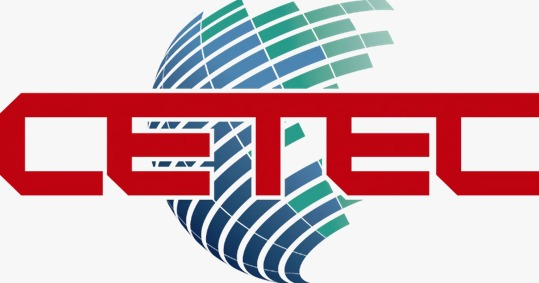





Licenciatura en Ingeniería en Sistemas Computacionales.

**Amanda Carolina Granados Vásquez.**

Actividad 3

Relaciones avanzadas, manejo de errores y principios de diseño.

**Ing. Jessica de Águila.**

Programación Orientada a Objetos.

14 de octubre de 2026

# Ejercicio 1: constructores y documentación de las clases


Crearemos las clases principales de la Tiendita y utilizaremos correctamente el constructor` _init_.` Este método permite preparar los atributos cuando creamos un objeto.

In [15]:
# Actividad 3: Mi Proyecto Tiendita
# Importamos las herramientas que utilizaremos.

from abc import ABC, abstractmethod
from typing import Protocol
import json
import threading


class Describible(Protocol):
    """Contrato para los objetos que pueden describir su información."""

    def describir(self) -> str:
        """Devuelve una descripción del objeto."""
        ...


class StockInsuficienteError(Exception):
    """Error que se produce cuando no hay unidades suficientes."""
    pass

# Qué estamos haciendo?
ABC y abstractmethod permitirán crear una clase abstracta.

Protocol servirá para definir un contrato que deben cumplir ciertos objetos.

Json permitirá guardar y recuperar los datos de los productos.

Threading permitirá demostrar el uso de hilos.

StockInsuficienteError será nuestra propia excepción para controlar las ventas que superen las existencias.

# Clases Principales

In [16]:
class Categoria:
    """Representa la categoría a la que pertenece un producto."""

    def __init__(self, nombre="General"):
        self.nombre = nombre


class Producto(ABC):
    """Clase abstracta que establece las características comunes
    y las operaciones básicas de los productos de la tiendita.
    """

    def __init__(self, nombre, precio, cantidad, categoria):
        self.nombre = nombre
        self._precio = 0
        self.precio = precio
        self.cantidad = cantidad
        self.categoria = categoria

    @property
    def precio(self):
        """Permite consultar el precio del producto."""
        return self._precio

    @precio.setter
    def precio(self, nuevo_precio):
        """Valida que el precio sea mayor que cero."""
        if nuevo_precio <= 0:
            raise ValueError("El precio debe ser mayor que cero.")
        self._precio = nuevo_precio

    @abstractmethod
    def describir(self):
        """Cada tipo de producto debe implementar su descripción."""
        pass

    def vender(self, cantidad=1, *cantidades_extra):
        """Vende una o varias cantidades y controla las existencias."""
        total = cantidad + sum(cantidades_extra)

        if total <= 0:
            raise ValueError("La cantidad debe ser mayor que cero.")

        if total > self.cantidad:
            raise StockInsuficienteError(
                f"No hay suficientes unidades de {self.nombre}."
            )

        self.cantidad -= total
        return f"Venta realizada: {total} unidad(es) de {self.nombre}."

    def actualizar_precio(self, nuevo_precio=None, descuento=0):
        """Permite establecer un precio o aplicar un descuento."""

        if nuevo_precio is not None:
            self.precio = nuevo_precio

        elif 0 < descuento < 100:
            self.precio = self.precio * (1 - descuento / 100)

        else:
            raise ValueError(
                "Indique un precio nuevo o un descuento entre 0 y 100."
            )


class ProductoAlimento(Producto):
    """Representa alimentos que se venden en la tiendita."""

    def __init__(self, nombre, precio, cantidad, categoria, marca):
        super().__init__(nombre, precio, cantidad, categoria)
        self.marca = marca

    def describir(self):
        """Sobrescribe el método para mostrar datos del alimento."""
        return (
            f"Producto: {self.nombre}\n"
            f"Marca: {self.marca}\n"
            f"Categoría: {self.categoria.nombre}\n"
            f"Precio: ${self.precio:.2f}\n"
            f"Existencias: {self.cantidad}"
        )


class ProductoLimpieza(Producto):
    """Representa artículos de limpieza de la tiendita."""

    def describir(self):
        """Proporciona una descripción propia de limpieza."""
        return (
            f"Artículo de limpieza: {self.nombre}\n"
            f"Categoría: {self.categoria.nombre}\n"
            f"Precio: ${self.precio:.2f}\n"
            f"Existencias: {self.cantidad}"
        )

# Explicación:

Categoria identifica el grupo de un producto.

Producto es abstracta: establece características comunes y operaciones que compartirán los productos.

ProductoAlimento hereda de Producto y agrega la marca.

ProductoLimpieza representa otra clase de producto y proporciona su propia descripción.

super`()._init_(...) `ejecuta el constructor de la clase padre.

@property y @precio.setter permiten validar el precio antes de modificarlo.

# Inventario

In [17]:
class Inventario:
    """Administra la lista de productos de la tiendita."""

    def __init__(self):
        self.productos = []

    def agregar_producto(self, producto):
        """Agrega un producto al inventario."""
        self.productos.append(producto)

    def mostrar_inventario(self):
        """Muestra la información de todos los productos."""
        for producto in self.productos:
            print(producto.describir())
            print("-" * 30)

    def buscar_producto(self, nombre):
        """Busca un producto por su nombre."""
        for producto in self.productos:
            if producto.nombre.lower() == nombre.lower():
                return producto
        return None

Aquí aplicamos una relación entre clases:
El inventario contiene una lista de productos.

# Comprobación del código

In [18]:
# Creamos una categoría.
categoria_alimentos = Categoria("Alimentos")

# Creamos dos productos.
arroz = ProductoAlimento(
    "Arroz", 1.25, 20, categoria_alimentos, "Marca A"
)

galletas = ProductoAlimento(
    "Galletas", 0.75, 15, categoria_alimentos, "Marca B"
)

# Creamos el inventario y agregamos los productos.
inventario = Inventario()
inventario.agregar_producto(arroz)
inventario.agregar_producto(galletas)

# Mostramos los productos registrados.
print("=== INVENTARIO INICIAL ===")
inventario.mostrar_inventario()

=== INVENTARIO INICIAL ===
Producto: Arroz
Marca: Marca A
Categoría: Alimentos
Precio: $1.25
Existencias: 20
------------------------------
Producto: Galletas
Marca: Marca B
Categoría: Alimentos
Precio: $0.75
Existencias: 15
------------------------------


# Ejercicio 2. Sobrecarga y sobrescritura.

Objetivo: crear una subclase que sobrescriba un método heredado y explicar la diferencia entre sobrecarga y sobrescritura.

# Paso 1. Crear una clase nueva.

In [19]:
# Nueva subclase para las bebidas.
class ProductoBebida(Producto):
    """Representa una bebida de la tiendita."""

    def _init_(self, nombre, precio, cantidad, categoria, marca):
        super()._init_(nombre, precio, cantidad, categoria)
        self.marca = marca

    def mostrar_info(self):
        """Sobrescribe el método heredado."""
        return (
            f"Producto: {self.nombre}\n"
            f"Tipo: Bebida\n"
            f"Marca: {self.marca}\n"
            f"Categoría: {self.categoria.nombre}\n"
            f"Precio: ${self.precio:.2f}\n"
            f"Existencias: {self.cantidad}"
        )

# Qué hace este código?

ProductoBebida`(Producto):` hereda las características de Producto.

super`()._init_(...): `inicializa los atributos heredados.

`self.`marca: agrega la marca de la bebida.

`mostrar_info(): `sobrescribe el método para mostrar información específica de una bebida.

# Comprobación del código
Nueva Clase

In [20]:
# Redefinimos ProductoBebida corrigiendo el constructor e implementando el método obligatorio 'describir'
class ProductoBebida(Producto):
    """Representa una bebida de la tiendita."""

    def __init__(self, nombre, precio, cantidad, categoria, marca):
        super().__init__(nombre, precio, cantidad, categoria)
        self.marca = marca

    def describir(self):
        """Implementa y sobrescribe el método abstracto de la clase padre."""
        return (
            f"Producto: {self.nombre}\n"
            f"Tipo: Bebida\n"
            f"Marca: {self.marca}\n"
            f"Categoría: {self.categoria.nombre}\n"
            f"Precio: ${self.precio:.2f}\n"
            f"Existencias: {self.cantidad}"
        )

# Creamos una bebida.
bebida = ProductoBebida(
    "Gaseosa", 1.00, 12, categoria_alimentos, "Marca C"
)

# Mostramos su información.
print("=== PRODUCTO BEBIDA ===")
print(bebida.describir())

=== PRODUCTO BEBIDA ===
Producto: Gaseosa
Tipo: Bebida
Marca: Marca C
Categoría: Alimentos
Precio: $1.00
Existencias: 12


Usamos categoria_alimentos porque es la categoría que aparece en tu código actual.

# Diferencia entre sobrecarga y sobrescritura.

La sobrecarga simulada permite utilizar un mismo método con diferentes argumentos, como actualizar`_precio() `en la Actividad 2.

La sobrescritura ocurre cuando una subclase redefine un método heredado, como `mostrar_info() `en ProductoBebida, para presentar información específica. Ambos conceptos permiten adaptar el comportamiento del programa según las necesidades.

# Ejercicio 3. Interfaces o protocolos.

Objetivo: comprobar que diferentes clases cumplen un mismo contrato.

# Comprobación del contrato


In [23]:
# Ambas clases implementan el método describir() cumpliendo con el protocolo Describible.
print("=== DESCRIPCIÓN ARROZ ===")
print(arroz.describir())
print("-" * 25)
print("=== DESCRIPCIÓN BEBIDA ===")
print(bebida.describir())

=== DESCRIPCIÓN ARROZ ===
Producto: Arroz
Marca: Marca A
Categoría: Alimentos
Precio: $1.25
Existencias: 20
-------------------------
=== DESCRIPCIÓN BEBIDA ===
Producto: Gaseosa
Tipo: Bebida
Marca: Marca C
Categoría: Alimentos
Precio: $1.00
Existencias: 12


# Cómo configurar el ambiente  de desarrollo?

Para ejecutar el proyecto instalaría Python 3.10 o una versión posterior compatible. También utilizaría Google Colab, que permite ejecutar Python desde el navegador. El proyecto utiliza módulos estándar como "abc", "json" y "threading", por lo que no necesita instalar dependencias externas. Si otra persona desea ejecutarlo en su computadora, deberá tener Python instalado y guardar el código en un archivo ".py" o en un cuaderno compatible.

# Ejercicio 4. Excepción personalizada.

Objetivo: mostrar un mensaje adecuado cuando no existan suficientes productos para realizar una venta.

**Paso 1. Crear la excepción**

In [24]:
class StockInsuficienteError(Exception):
    """Error cuando no hay suficientes productos."""
    pass

Probar una venta:

In [25]:
def vender_seguro(producto, cantidad):
    if cantidad <= 0:
        raise ValueError("La cantidad debe ser positiva.")

    if cantidad > producto.cantidad:
        raise StockInsuficienteError(
            "No hay suficientes unidades en inventario."
        )

    producto.vender(cantidad)


try:
    vender_seguro(arroz, 100)
except StockInsuficienteError as error:
    print("Error de venta:", error)
except ValueError as error:
    print("Cantidad inválida:", error)

Error de venta: No hay suficientes unidades en inventario.


Entonces `raise` genera un error cuando no se cumple una condición, mientras que try/except permite capturarlo y mostrar un mensaje sin detener todo el programa.

# Ejercicio 5. Hilos o threads.
Objetivo: ejecutar tareas en paralelo con el módulo threading.

Un hilo o `thread` permite ejecutar una tarea dentro de un programa. Sus estados principales son nuevo, listo, en ejecución, bloqueado o en espera, y terminado. Un hilo nuevo todavía no comienza. Cuando se inicia, puede esperar su turno para ejecutarse. Durante la ejecución puede quedar en espera de algún recurso. Después continúa o finaliza su tarea. Los hilos permiten realizar varias actividades de manera concurrente.

# Creación de dos tareas concurrentes.


In [30]:
import threading

def revisar_producto(producto):
    print(f"Revisando: {producto.nombre}\n")
    # Corregido: Se usa describir() que es el método real de las clases
    print(producto.describir())
    print("-" * 25)

hilo1 = threading.Thread(target=revisar_producto, args=(arroz,))
hilo2 = threading.Thread(target=revisar_producto, args=(bebida,))

hilo1.start()
hilo2.start()

hilo1.join()
hilo2.join()

print("Revisión finalizada.")

Revisando: Arroz

Producto: Arroz
Marca: Marca A
Categoría: Alimentos
Precio: $1.25
Existencias: 20
-------------------------
Revisando: Gaseosa

Producto: Gaseosa
Tipo: Bebida
Marca: Marca C
Categoría: Alimentos
Precio: $1.00
Existencias: 12
-------------------------
Revisión finalizada.


Entonces;

`Thread()` crea cada hilo.

`start()` inicia la tarea.

`join() `espera a que termine cada hilo.

NOTA: El orden de los mensajes puede variar porque las tareas se ejecutan concurrentemente.

# Ejercicio 6. Guardar y leer archivos JSON.

Objetivo: guardar la información de un producto y recuperarla desde un archivo.

Paso 1. Guardar el producto

In [27]:
import json

datos = {
    "nombre": arroz.nombre,
    "precio": arroz.precio,
    "cantidad": arroz.cantidad,
    "categoria": arroz.categoria.nombre,
    "marca": arroz.marca
}

with open("producto.json", "w", encoding="utf-8") as archivo:
    json.dump(datos, archivo, indent=4, ensure_ascii=False)

print("Producto guardado correctamente.")

Producto guardado correctamente.


# 2. Leer y reconstruir el producto.

In [31]:
try:
    with open("producto.json", "r", encoding="utf-8") as archivo:
        datos = json.load(archivo)

    categoria_guardada = Categoria(datos["categoria"])

    producto_recuperado = ProductoAlimento(
        datos["nombre"],
        datos["precio"],
        datos["cantidad"],
        categoria_guardada,
        datos["marca"]
    )

    print("=== PRODUCTO RECUPERADO ===")
    # Corregido: Se utiliza describir() en lugar del inexistente mostrar_info()
    print(producto_recuperado.describir())

except FileNotFoundError:
    print("Error: no se encontró el archivo.")

except (json.JSONDecodeError, KeyError, TypeError, ValueError) as error:
    print("Error al leer los datos:", error)

=== PRODUCTO RECUPERADO ===
Producto: Arroz
Marca: Marca A
Categoría: Alimentos
Precio: $1.25
Existencias: 20


¿Qué conseguimos con esto?

Guardamos los datos en `JSON` y creamos nuevamente un objeto ProductoAlimento a partir de ellos. Los errores comunes de lectura y de datos se controlan con `try/except.`

# Ejercicio 7. Composición en lugar de herencia.

Objetivo: demostrar cómo las clases pueden relacionarse sin crear una jerarquía innecesaria.

Como bien hemos visto que ya tenemos un ejemplo útil de composición: un producto recibe un objeto Categoria. Por ejemplo, el arroz pertenece a la categoría de alimentos, pero la categoría no necesita heredar de la clase Producto.
# Paso 1. Crear otra categoría

In [35]:
# Creamos una categoría independiente.
categoria_bebidas = Categoria("Bebidas")

# La bebida contiene una categoría.
bebida_nueva = ProductoBebida(
    "Jugo AMANDA", 5.50, 10, categoria_bebidas, "Marca D"
)

# Corregido: Se utiliza describir() en lugar de mostrar_info()
print(bebida_nueva.describir())

Producto: Jugo AMANDA
Tipo: Bebida
Marca: Marca D
Categoría: Bebidas
Precio: $5.50
Existencias: 10


# Composición en La Tiendita...

Un problema de la herencia es crear demasiadas subclases para representar características que pueden cambiar. En mi proyecto utilice composición porque cada producto recibe un objeto "Categoria". Así podemos crear categorías como Alimentos y Bebidas sin crear una subclase diferente para cada categoría. Esto hace que el programa sea más flexible y fácil de mantener.

# Ejercicio 8. Polimorfismo y principios SOLID.

Objetivo: utilizar el mismo método con distintos tipos de productos y aplicar buenas prácticas de diseño.

# Paso 1. Demostrar el polimorfismo

In [37]:
# Reunimos productos de diferentes tipos.
productos = [arroz, galletas, bebida]

print("=== INVENTARIO POLIMÓRFICO ===")

for producto in productos:
    # Corregido: Se utiliza describir() que es el método común y polimórfico
    print(producto.describir())
    print("-" * 25)

=== INVENTARIO POLIMÓRFICO ===
Producto: Arroz
Marca: Marca A
Categoría: Alimentos
Precio: $1.25
Existencias: 20
-------------------------
Producto: Galletas
Marca: Marca B
Categoría: Alimentos
Precio: $0.75
Existencias: 15
-------------------------
Producto: Gaseosa
Tipo: Bebida
Marca: Marca C
Categoría: Alimentos
Precio: $1.00
Existencias: 12
-------------------------


# ¿Qué debe suceder?
El programa utiliza mostrar_`info()` para todos los productos, pero cada objeto presenta su información según su propia clase.
Arroz y Galletas muestran los datos de ProductoAlimento.
Gaseosa muestra los datos de ProductoBebida.
Esto demuestra el polimorfismo: un mismo método tiene comportamientos específicos según el objeto.

# Paso 2. Aplicar tres principios SOLID

# Principios SOLID aplicados

**1. Responsabilidad única (SRP):** cada clase tiene una función específica. "Categoria" representa categorías, "Producto" define los productos y "Inventario" los organiza.

**2. Abierto/cerrado (OCP):** podemos agregar nuevas subclases, como "ProductoBebida", sin modificar la clase base para cada nuevo tipo de producto.

**3. Sustitución de Liskov (LSP):** los objetos de "ProductoAlimento" y "ProductoBebida" pueden utilizarse donde se espera un objeto "Producto", siempre que respeten el comportamiento definido por la clase base.

In [40]:
def ejecutar_tiendita():
    categoria = Categoria("Bebidas")

    productos = [
        ProductoAlimento("Arroz", 1.25, 20, categoria_alimentos, "Marca A"),
        ProductoAlimento("Galletas", 0.75, 15, categoria_alimentos, "Marca B"),
        ProductoBebida("Gaseosa", 1.00, 12, categoria, "Marca C")
    ]

    print("=== MI PROYECTO LA TIENDITA ===")

    for producto in productos:
        # Corregido: Se utiliza describir() en lugar de mostrar_info()
        print(producto.describir())
        print("-" * 25)

    print("=== VENTA ===")
    try:
        vender_seguro(productos[0], 2)
        print("Venta completada.")
    except (StockInsuficienteError, ValueError) as error:
        print("No se pudo realizar la venta:", error)

# Corregido: Se utiliza __name__ y __main__ con doble guion bajo
if __name__ == "__main__":
    ejecutar_tiendita()

=== MI PROYECTO LA TIENDITA ===
Producto: Arroz
Marca: Marca A
Categoría: Alimentos
Precio: $1.25
Existencias: 20
-------------------------
Producto: Galletas
Marca: Marca B
Categoría: Alimentos
Precio: $0.75
Existencias: 15
-------------------------
Producto: Gaseosa
Tipo: Bebida
Marca: Marca C
Categoría: Bebidas
Precio: $1.00
Existencias: 12
-------------------------
=== VENTA ===
Venta completada.


# Código: Mi Proyecto La Tiendita.

In [47]:
# ============================================
# ACTIVIDAD 3: MI PROYECTO LA TIENDITA
# Programación Orientada a Objetos - Python
# ============================================

from abc import ABC, abstractmethod
from typing import Protocol
import json
import threading


# EJERCICIO 1: CATEGORÍA Y DOCUMENTACIÓN

class Categoria:
    """Representa la categoría de un producto."""

    def __init__(self, nombre):
        self.nombre = nombre


# EJERCICIO 4: EXCEPCIÓN PERSONALIZADA

class StockInsuficienteError(Exception):
    """Error cuando no hay suficientes unidades."""
    pass


# EJERCICIO 3: INTERFAZ O PROTOCOLO

class Describible(Protocol):
    """Contrato para describir objetos."""

    def mostrar_info(self) -> str:
        ...


# CLASE ABSTRACTA PRODUCTO

class Producto(ABC):
    """Clase base para los productos de la tiendita."""

    def __init__(self, nombre, precio, cantidad, categoria):
        self.nombre = nombre
        self.precio = precio
        self.cantidad = cantidad
        self.categoria = categoria

    @property
    def precio(self):
        return self._precio

    @precio.setter
    def precio(self, nuevo_precio):
        if nuevo_precio <= 0:
            raise ValueError("El precio debe ser mayor que cero.")
        self._precio = nuevo_precio

    @abstractmethod
    def mostrar_info(self):
        """Cada subclase muestra su propia información."""
        pass

    def vender(self, cantidad=1):
        if cantidad <= 0:
            raise ValueError("La cantidad debe ser positiva.")

        if cantidad > self.cantidad:
            raise StockInsuficienteError(
                "No hay suficientes unidades en inventario."
            )

        self.cantidad -= cantidad
        print(f"Venta realizada: {cantidad} unidad(es) de {self.nombre}.")

    # SOBRECARGA SIMULADA: EJEMPLO DE ACTIVIDAD 2.
    # Permite indicar un precio nuevo o aplicar un descuento.
    # Python simula la sobrecarga con argumentos opcionales.
    def actualizar_precio(self, nuevo_precio=None, descuento=0):
        if nuevo_precio is not None:
            self.precio = nuevo_precio
        elif 0 < descuento < 100:
            self.precio *= (1 - descuento / 100)
        else:
            raise ValueError("Indique un precio o descuento válido.")


# EJERCICIO 2: HERENCIA Y SOBRESCRITURA

class ProductoAlimento(Producto):
    """Representa alimentos de la tiendita."""

    def __init__(self, nombre, precio, cantidad, categoria, marca):
        super().__init__(nombre, precio, cantidad, categoria)
        self.marca = marca

    # SOBRESCRITURA (OVERRIDE): redefine el método heredado.
    def mostrar_info(self):
        return (
            f"Producto: {self.nombre}\n"
            f"Tipo: Alimento\n"
            f"Marca: {self.marca}\n"
            f"Categoría: {self.categoria.nombre}\n"
            f"Precio: ${self.precio:.2f}\n"
            f"Existencias: {self.cantidad}"
        )


class ProductoBebida(Producto):
    """Representa bebidas de la tiendita."""

    def __init__(self, nombre, precio, cantidad, categoria, marca):
        super().__init__(nombre, precio, cantidad, categoria)
        self.marca = marca

    # SOBRESCRITURA (OVERRIDE): muestra datos de una bebida.
    def mostrar_info(self):
        return (
            f"Producto: {self.nombre}\n"
            f"Tipo: Bebida\n"
            f"Marca: {self.marca}\n"
            f"Categoría: {self.categoria.nombre}\n"
            f"Precio: ${self.precio:.2f}\n"
            f"Existencias: {self.cantidad}"
        )


# INVENTARIO: AGRUPA LOS PRODUCTOS

class Inventario:
    """Administra la lista de productos."""

    def __init__(self):
        self.productos = []

    def agregar_producto(self, producto):
        self.productos.append(producto)

    def mostrar_inventario(self):
        for producto in self.productos:
            print(producto.mostrar_info())
            print("-" * 30)


# EJERCICIO 5: CONCURRENCIA CON THREADING

def revisar_producto(producto):
    print(f"Hilo revisando: {producto.nombre}")
    print(producto.mostrar_info())


def revisar_en_paralelo(productos):
    hilos = []

    for producto in productos:
        hilo = threading.Thread(
            target=revisar_producto,
            args=(producto,)
        )
        hilos.append(hilo)
        hilo.start()

    for hilo in hilos:
        hilo.join()

    print("Revisión de productos finalizada.")


# EJERCICIO 6: GUARDAR Y LEER JSON

def guardar_producto(producto, nombre_archivo="producto.json"):
    datos = {
        "nombre": producto.nombre,
        "precio": producto.precio,
        "cantidad": producto.cantidad,
        "categoria": producto.categoria.nombre,
        "marca": producto.marca,
        "tipo": (
            "bebida" if isinstance(producto, ProductoBebida)
            else "alimento"
        )
    }

    try:
        with open(nombre_archivo, "w", encoding="utf-8") as archivo:
            json.dump(datos, archivo, indent=4, ensure_ascii=False)

        print("Producto guardado correctamente.")

    except OSError as error:
        print("No se pudo guardar el archivo:", error)


def leer_producto(nombre_archivo="producto.json"):
    try:
        with open(nombre_archivo, "r", encoding="utf-8") as archivo:
            datos = json.load(archivo)

        categoria = Categoria(datos["categoria"])

        if datos["tipo"] == "bebida":
            clase = ProductoBebida
        elif datos["tipo"] == "alimento":
            clase = ProductoAlimento
        else:
            raise ValueError("Tipo de producto desconocido.")

        producto = clase(
            datos["nombre"],
            datos["precio"],
            datos["cantidad"],
            categoria,
            datos["marca"]
        )

        print("Producto recuperado del archivo:")
        print(producto.mostrar_info())
        return producto

    except FileNotFoundError:
        print("Error: el archivo no existe.")
    except (json.JSONDecodeError, KeyError, TypeError, ValueError) as error:
        print("Error en los datos del archivo:", error)
    except OSError as error:
        print("Error al leer el archivo:", error)

    return None


# EJERCICIO 7: COMPOSICIÓN
# Cada producto contiene un objeto Categoria.
# No es necesario que Categoria herede de Producto.


# EJERCICIO 8: APLICACIÓN INTEGRADORA

def ejecutar_tiendita():
    # Creamos categorías.
    alimentos = Categoria("Alimentos")
    bebidas = Categoria("Bebidas")

    # Creamos productos.
    arroz = ProductoAlimento(
        "Arroz", 1.25, 20, alimentos, "Marca A"
    )
    galletas = ProductoAlimento(
        "Galletas", 0.75, 15, alimentos, "Marca B"
    )
    gaseosa = ProductoBebida(
        "Gaseosa", 1.00, 12, bebidas, "Marca C"
    )

    # Creamos el inventario.
    inventario = Inventario()

    for producto in [arroz, galletas, gaseosa]:
        inventario.agregar_producto(producto)

    print("\n=== MI PROYECTO LA TIENDITA ===")
    print("\n=== INVENTARIO INICIAL ===")
    inventario.mostrar_inventario()

    # Probamos la venta y la excepción.
    print("\n=== PRUEBA DE VENTA ===")

    try:
        arroz.vender(2)
        arroz.vender(100)
    except StockInsuficienteError as error:
        print("Error de venta:", error)
    except ValueError as error:
        print("Cantidad inválida:", error)

    # Probamos la actualización del precio.
    print("\n=== ACTUALIZACIÓN DE PRECIO ===")
    galletas.actualizar_precio(descuento=10)
    print(galletas.mostrar_info())

    # Probamos el polimorfismo.
    print("\n=== POLIMORFISMO ===")
    for producto in inventario.productos:
        print(producto.mostrar_info())
        print("-" * 30)

    # Probamos los hilos.
    print("\n=== REVISIÓN CON HILOS ===")
    revisar_en_paralelo(inventario.productos)

    # Guardamos y recuperamos un producto.
    print("\n=== ARCHIVO JSON ===")
    guardar_producto(gaseosa)
    leer_producto()

    print("\n=== FIN DEL PROGRAMA ===")


# Ejecutar la aplicación.
if __name__ == "__main__":
    ejecutar_tiendita()


=== MI PROYECTO LA TIENDITA ===

=== INVENTARIO INICIAL ===
Producto: Arroz
Tipo: Alimento
Marca: Marca A
Categoría: Alimentos
Precio: $1.25
Existencias: 20
------------------------------
Producto: Galletas
Tipo: Alimento
Marca: Marca B
Categoría: Alimentos
Precio: $0.75
Existencias: 15
------------------------------
Producto: Gaseosa
Tipo: Bebida
Marca: Marca C
Categoría: Bebidas
Precio: $1.00
Existencias: 12
------------------------------

=== PRUEBA DE VENTA ===
Venta realizada: 2 unidad(es) de Arroz.
Error de venta: No hay suficientes unidades en inventario.

=== ACTUALIZACIÓN DE PRECIO ===
Producto: Galletas
Tipo: Alimento
Marca: Marca B
Categoría: Alimentos
Precio: $0.68
Existencias: 15

=== POLIMORFISMO ===
Producto: Arroz
Tipo: Alimento
Marca: Marca A
Categoría: Alimentos
Precio: $1.25
Existencias: 18
------------------------------
Producto: Galletas
Tipo: Alimento
Marca: Marca B
Categoría: Alimentos
Precio: $0.68
Existencias: 15
------------------------------
Producto: Gaseos